<a href="https://colab.research.google.com/github/AdwaaNasser/Burnout-Models/blob/main/Bayyinah_Burnout_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bayyinah –  Regression Models (`burnout_score`)

**Goal:** predict each employee's `burnout_score` (0–10)



**Models:**

1. Dummy (baseline)
2. Linear models: Linear Regression, Ridge, Lasso
3. HistGradientBoosting
4. Random Forest
5. XGBoost

Every model is trained twice: with `FEATURES_FULL` (26 features) and with `FEATURES_HR` (22 features, without sleep, exercise and therapy).


## 0. Setup

In [ ]:
import os, json, time, zipfile, warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import KFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, make_scorer,
                             accuracy_score, f1_score, cohen_kappa_score)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from scipy.stats import loguniform, randint, uniform

try:
    from xgboost import XGBRegressor
    import xgboost
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

PREP_DIR = "prepared"
OUT_DIR = "models"
RANDOM_STATE = 42
TARGET = "burnout_score"
LEVELS = ["Low", "Moderate", "High", "Severe"]

print("XGBoost available:", HAS_XGB)

XGBoost available: True


In [ ]:
# Get the prepared/ folder: upload prepared.zip (or the files) if it isn't here yet.
# In Colab you can also mount Google Drive and set PREP_DIR to the Drive path.
if not os.path.isdir(PREP_DIR):
    from google.colab import files
    print("Upload prepared.zip (or Bayyinah_prepared_data.zip) from the data preparation step")
    uploaded = files.upload()
    for name in uploaded:
        if name.endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall(".")
assert os.path.isdir(PREP_DIR), "prepared/ folder not found"

In [ ]:
X_train = pd.read_csv(f"{PREP_DIR}/X_train.csv")
X_test = pd.read_csv(f"{PREP_DIR}/X_test.csv")
y_train = pd.read_csv(f"{PREP_DIR}/y_train_reg.csv")[TARGET]
y_test = pd.read_csv(f"{PREP_DIR}/y_test_reg.csv")[TARGET]
y_test_level = pd.read_csv(f"{PREP_DIR}/y_test_clf.csv")["burnout_level"]   # only used in section 8

with open(f"{PREP_DIR}/feature_lists.json") as f:
    feature_lists = json.load(f)

FEATURES_FULL = feature_lists["FEATURES_FULL"]
FEATURES_HR = feature_lists["FEATURES_HR"]
FEATURE_SETS = {"FULL": FEATURES_FULL, "HR": FEATURES_HR}

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("FULL:", len(FEATURES_FULL), "features | HR:", len(FEATURES_HR), "features")
print()
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("numpy       ", np.__version__)
print("joblib      ", joblib.__version__)
if HAS_XGB:
    print("xgboost     ", xgboost.__version__)

X_train: (76804, 26) | X_test: (19202, 26)
FULL: 26 features | HR: 22 features

pandas       3.1.1
scikit-learn 1.9.1
numpy        2.5.4
joblib       1.6.0
xgboost      3.4.1


### Preprocessors

we load the two preprocessors that we saved in the data preparation notebook, one for the FULL model and one for the HR model.

One thing to keep in mind is that `.pkl` files may not work if we use a different scikit-learn version than the one used when saving them. If we have a problem loading them, we can create them again using `feature_lists.json` and the same preprocessing steps:

- For numeric columns, we fill missing values using the median and then scale them.
- For `company_size`, we use ordinal encoding based on the company size order (Startup, Small, Mid, Large, Enterprise).
- For the other categorical columns, we use one-hot encoding.

We also use `clone(...)` to create a new copy of each preprocessor. This is important because we want it to learn from the training data only, without using information from the test data. It also makes sure that each cross-validation fold has its own fitted preprocessor.

In [ ]:
def build_preprocessor(feature_list):
    """Same preprocessing as the data preparation notebook (fallback if the .pkl can't be loaded)."""
    num = [c for c in feature_list if c in feature_lists["numeric"]]
    ordi = [c for c in feature_list if c in feature_lists["categorical_ordinal"]]
    cat = [c for c in feature_list if c in feature_lists["categorical_onehot"]]
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("company_size", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                   ("encoder", OrdinalEncoder(categories=[feature_lists["company_size_order"]]))]), ordi),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ], remainder="drop")

PREPROCESSORS = {}
for name, fname in [("FULL", "preprocessor_full.pkl"), ("HR", "preprocessor_hr.pkl")]:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error")          # a version-mismatch warning counts as a failure
            prep = joblib.load(f"{PREP_DIR}/{fname}")
        PREPROCESSORS[name] = clone(prep)
        print(f"{name}: loaded {fname}")
    except Exception as e:
        PREPROCESSORS[name] = build_preprocessor(FEATURE_SETS[name])
        print(f"{name}: could not load {fname} ({type(e).__name__}), rebuilt from feature_lists.json")

FULL: loaded preprocessor_full.pkl
HR: loaded preprocessor_hr.pkl


## 1. Sanity checks

Quick checks before training anything: right shapes, no missing values, and no ID / leakage / target column hiding in X.

In [ ]:
forbidden = ["employee_id", "stress_score", "phq9_score", "phq9_category", "gad7_score", "gad7_category",
             "seeks_mental_health_support", "job_change_intention", "burnout_score", "burnout_level"]

assert X_train.columns.tolist() == FEATURES_FULL
assert not [c for c in forbidden if c in X_train.columns]
assert len(X_train) == len(y_train) and len(X_test) == len(y_test) == len(y_test_level)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

print("OK – no ID, leakage or target columns in X, no missing values.\n")
print(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(3))
print(f"\nShare of scores exactly at 0 or 10: {((y_train == 0) | (y_train == 10)).mean() * 100:.1f}%")

OK – no ID, leakage or target columns in X, no missing values.

           train       test
count  76804.000  19202.000
mean       5.394      5.401
std        2.669      2.667
min        0.000      0.000
25%        3.500      3.500
50%        5.400      5.400
75%        7.400      7.400
max       10.000     10.000

Share of scores exactly at 0 or 10: 8.6%


**Note:** about 9% of the burnout scores are exactly 0 or 10, which suggests the scores were cut at these limits when the data was generated. Since a linear model doesn't know these limits, it can sometimes predict values like 11 or -0.5. We **clip every prediction to stay between 0 and 10**, because a burnout score outside this range doesn't make sense.

## 2. How we evaluate

- **MAE**
- **RMSE**
- **R²**

All tuning and model choice use **5-fold cross-validation**.

In [ ]:
def clip_score(pred):
    return np.clip(pred, 0, 10)

def mae_clipped(y, pred):
    return mean_absolute_error(y, clip_score(pred))

def rmse_clipped(y, pred):
    return np.sqrt(mean_squared_error(y, clip_score(pred)))

def r2_clipped(y, pred):
    return r2_score(y, clip_score(pred))

SCORING = {
    "MAE": make_scorer(mae_clipped, greater_is_better=False),
    "RMSE": make_scorer(rmse_clipped, greater_is_better=False),
    "R2": make_scorer(r2_clipped),
}
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model, feature_set):
    return Pipeline([("prep", clone(PREPROCESSORS[feature_set])), ("model", model)])

cv_rows = []        # one row per model x feature set (CV results)
best_pipes = {}     # (model name, feature set) -> tuned pipeline (refitted on the full training set)

def record(name, fs, pipe, params, seconds):
    """Run 5-fold CV for the final settings of a model and store the results."""
    r = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    cv_rows.append({
        "model": name, "features": fs,
        "CV_MAE": -r["test_MAE"].mean(), "CV_MAE_std": r["test_MAE"].std(),
        "CV_RMSE": -r["test_RMSE"].mean(), "CV_R2": r["test_R2"].mean(),
        "tuning_seconds": round(seconds, 1), "best_params": params,
    })
    best_pipes[(name, fs)] = clone(pipe).fit(X_train, y_train)
    print(f"{name:<22} {fs:<4}  CV MAE {-r['test_MAE'].mean():.4f}  R2 {r['test_R2'].mean():.4f}  ({seconds:.0f}s)")

## 3. Baseline (Dummy)

The Dummy model always predicts the average burnout score of the training set. Every real model must beat it clearly, otherwise it learned nothing.

In [ ]:
for fs in FEATURE_SETS:
    record("Dummy (mean)", fs, make_pipeline(DummyRegressor(strategy="mean"), fs), {}, 0)

Dummy (mean)           FULL  CV MAE 2.2042  R2 -0.0000  (0s)
Dummy (mean)           HR    CV MAE 2.2042  R2 -0.0000  (0s)


## 4. Linear models


We tried three of them:
- **Linear Regression:** the basic version, nothing to tune.
- **Ridge:** makes all the coefficients a bit smaller so the model doesn't rely too much on one feature. This helps when some features are similar to each other.
- **Lasso:** also shrinks the coefficients, but it can set a useless feature's coefficient to exactly 0, so it shows us which features don't really matter.

Ridge and Lasso only have one setting to tune: `alpha`, which controls how much the coefficients get shrunk. Since it's just one setting, we simply try a few values with a grid search and keep the best one.

In [ ]:
for fs in FEATURE_SETS:
    t = time.time()
    record("Linear Regression", fs, make_pipeline(LinearRegression(), fs), {}, time.time() - t)

    t = time.time()
    search = GridSearchCV(make_pipeline(Ridge(), fs),
                          {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                          cv=CV, scoring=SCORING["MAE"], n_jobs=-1)
    search.fit(X_train, y_train)
    record("Ridge", fs, search.best_estimator_, search.best_params_, time.time() - t)

    t = time.time()
    search = GridSearchCV(make_pipeline(Lasso(max_iter=20000, random_state=RANDOM_STATE), fs),
                          {"model__alpha": [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]},
                          cv=CV, scoring=SCORING["MAE"], n_jobs=-1)
    search.fit(X_train, y_train)
    record("Lasso", fs, search.best_estimator_, search.best_params_, time.time() - t)

Linear Regression      FULL  CV MAE 1.1157  R2 0.7221  (0s)
Ridge                  FULL  CV MAE 1.1157  R2 0.7221  (5s)
Lasso                  FULL  CV MAE 1.1158  R2 0.7220  (4s)
Linear Regression      HR    CV MAE 1.4217  R2 0.5585  (0s)
Ridge                  HR    CV MAE 1.4217  R2 0.5585  (2s)
Lasso                  HR    CV MAE 1.4217  R2 0.5585  (4s)


## 5. HistGradientBoosting

A boosting model builds many small trees, each one fixing the mistakes of the ones before. It can catch non-linear patterns and interactions that linear models miss. The "Hist" version groups values into bins.

We use `RandomizedSearchCV`: it tries 15 random combinations instead of every combination

In [ ]:
HGB_PARAMS = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_iter": randint(150, 600),
    "model__max_leaf_nodes": randint(8, 64),
    "model__min_samples_leaf": randint(20, 200),
    "model__l2_regularization": loguniform(1e-3, 10),
}

for fs in FEATURE_SETS:
    t = time.time()
    search = RandomizedSearchCV(
        make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE, early_stopping=False), fs),
        HGB_PARAMS, n_iter=15, cv=CV, scoring=SCORING["MAE"], n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    record("HistGradientBoosting", fs, search.best_estimator_, search.best_params_, time.time() - t)

HistGradientBoosting   FULL  CV MAE 1.1340  R2 0.7146  (109s)
HistGradientBoosting   HR    CV MAE 1.4327  R2 0.5542  (92s)


## 6. Random Forest

Random Forest builds a lot of deep decision trees. Each tree only sees a random sample of the rows and features, and in the end we average all their predictions.



In [ ]:
RF_PARAMS = {
    "model__n_estimators": randint(100, 300),
    "model__max_depth": [None, 12, 20, 30],
    "model__min_samples_leaf": randint(2, 20),
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
}

X_sub = X_train.sample(frac=0.30, random_state=RANDOM_STATE)
y_sub = y_train.loc[X_sub.index]

for fs in FEATURE_SETS:
    t = time.time()
    search = RandomizedSearchCV(
        make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), fs),
        RF_PARAMS, n_iter=8, cv=CV, scoring=SCORING["MAE"], n_jobs=1, random_state=RANDOM_STATE)
    search.fit(X_sub, y_sub)
    record("Random Forest", fs, search.best_estimator_, search.best_params_, time.time() - t)

Random Forest          FULL  CV MAE 1.2338  R2 0.6726  (73s)
Random Forest          HR    CV MAE 1.4705  R2 0.5363  (67s)


## 7. XGBoost
Boosting library

In [ ]:
XGB_PARAMS = {
    "model__n_estimators": randint(200, 800),
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_depth": randint(3, 9),
    "model__min_child_weight": randint(1, 20),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(1e-2, 10),
}

if HAS_XGB:
    for fs in FEATURE_SETS:
        t = time.time()
        search = RandomizedSearchCV(
            make_pipeline(XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                       random_state=RANDOM_STATE, n_jobs=-1), fs),
            XGB_PARAMS, n_iter=15, cv=CV, scoring=SCORING["MAE"], n_jobs=1, random_state=RANDOM_STATE)
        search.fit(X_train, y_train)
        record("XGBoost", fs, search.best_estimator_, search.best_params_, time.time() - t)
else:
    print("XGBoost is not installed – skipped. In Colab it is pre-installed; elsewhere: pip install xgboost")

XGBoost                FULL  CV MAE 1.1278  R2 0.7163  (130s)
XGBoost                HR    CV MAE 1.4288  R2 0.5547  (130s)


## 8. Comparing models (cross-validation only)

The final model is chosen with the **CV** results, never with the test set. If two models are within about 0.01 MAE, we prefer the simpler and more explainable one.

In [ ]:
cv_table = pd.DataFrame(cv_rows)
cv_table_show = cv_table.drop(columns="best_params").sort_values(["features", "CV_MAE"])
display(cv_table_show.round(4).reset_index(drop=True))

,model,features,CV_MAE,CV_MAE_std,CV_RMSE,CV_R2,tuning_seconds
0,Linear Regression,FULL,1.1157,0.0041,1.4070,0.7221,0.0
1,Ridge,FULL,1.1157,0.0041,1.4070,0.7221,5.3
2,Lasso,FULL,1.1158,0.0041,1.4071,0.7220,4.2
3,XGBoost,FULL,1.1278,0.0047,1.4215,0.7163,130.4
4,HistGradientBoosting,FULL,1.1340,0.0024,1.4258,0.7146,108.8
5,Random Forest,FULL,1.2338,0.0062,1.5272,0.6726,73.3
6,Dummy (mean),FULL,2.2042,0.0157,2.6690,-0.0000,0.0
7,Linear Regression,HR,1.4217,0.0068,1.7734,0.5585,0.0
8,Ridge,HR,1.4217,0.0068,1.7734,0.5585,2.4
9,Lasso,HR,1.4217,0.0068,1.7734,0.5585,3.6


In [ ]:
def choose_model(fs, tolerance=0.01):
    """Best CV MAE for this feature set; if a simpler model is within `tolerance`, take the simpler one."""
    simplicity = ["Linear Regression", "Ridge", "Lasso", "HistGradientBoosting", "XGBoost", "Random Forest"]
    t = cv_table[(cv_table["features"] == fs) & (cv_table["model"] != "Dummy (mean)")]
    best_mae = t["CV_MAE"].min()
    close = t[t["CV_MAE"] <= best_mae + tolerance].copy()
    close["rank"] = close["model"].map(simplicity.index)
    return close.sort_values(["rank", "CV_MAE"]).iloc[0]["model"]

CHOSEN = {fs: choose_model(fs) for fs in FEATURE_SETS}
for fs, m in CHOSEN.items():
    row = cv_table[(cv_table["model"] == m) & (cv_table["features"] == fs)].iloc[0]
    print(f"{fs:<4} chosen: {m:<20} CV MAE {row['CV_MAE']:.4f} | R2 {row['CV_R2']:.4f} | params {row['best_params']}")

FULL chosen: Linear Regression    CV MAE 1.1157 | R2 0.7221 | params {}
HR   chosen: Linear Regression    CV MAE 1.4217 | R2 0.5585 | params {}


## 9. Test set results

 We report all tuned models for transparency, but the choice above was already made with CV.

In [ ]:
def test_metrics(pipe):
    pred = clip_score(pipe.predict(X_test))
    return {"test_MAE": mean_absolute_error(y_test, pred),
            "test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "test_R2": r2_score(y_test, pred)}

test_rows = []
for (name, fs), pipe in best_pipes.items():
    test_rows.append({"model": name, "features": fs, **test_metrics(pipe),
                      "chosen": "yes" if CHOSEN[fs] == name else ""})
test_table = pd.DataFrame(test_rows).sort_values(["features", "test_MAE"]).reset_index(drop=True)
display(test_table.round(4))

,model,features,test_MAE,test_RMSE,test_R2,chosen
0,Linear Regression,FULL,1.1173,1.4106,0.7201,yes
1,Ridge,FULL,1.1173,1.4106,0.7201,
2,Lasso,FULL,1.1174,1.4106,0.7202,
3,XGBoost,FULL,1.1243,1.4195,0.7166,
4,HistGradientBoosting,FULL,1.1292,1.4243,0.7147,
5,Random Forest,FULL,1.2240,1.5228,0.6739,
6,Dummy (mean),FULL,2.2045,2.6665,-0.0000,
7,Lasso,HR,1.4333,1.7938,0.5474,
8,Linear Regression,HR,1.4333,1.7940,0.5473,yes
9,Ridge,HR,1.4333,1.7940,0.5473,


### FULL vs HR

How much do we lose when the model can't see sleep, exercise and therapy? This tells the team what a real HR system can expect.

In [ ]:
full_vs_hr = test_table[test_table["chosen"] == "yes"].set_index("features")[["model", "test_MAE", "test_RMSE", "test_R2"]]
display(full_vs_hr.round(4))
d = full_vs_hr.loc["HR", "test_MAE"] - full_vs_hr.loc["FULL", "test_MAE"]
print(f"Without the personal columns the error grows by {d:.3f} points "
      f"and R2 drops from {full_vs_hr.loc['FULL', 'test_R2']:.3f} to {full_vs_hr.loc['HR', 'test_R2']:.3f}.")

,model,test_MAE,test_RMSE,test_R2
features,,,,
FULL,Linear Regression,1.1173,1.4106,0.7201
HR,Linear Regression,1.4333,1.7940,0.5473


Without the personal columns the error grows by 0.316 points and R2 drops from 0.720 to 0.547.


### Where does the chosen model make mistakes?

The overall MAE is just an average, so here we split the test employees by their real burnout level and check the error for each group. This shows if the model is worse for some groups than others.

We also look at the direction of the error: a positive number means the model predicts too high, and a negative one means it predicts too low.

In [ ]:
for fs in FEATURE_SETS:
    pipe = best_pipes[(CHOSEN[fs], fs)]
    pred = clip_score(pipe.predict(X_test))
    err = pd.DataFrame({"level": y_test_level, "abs_error": np.abs(y_test - pred), "error": pred - y_test})
    per_level = err.groupby("level").agg(n=("abs_error", "size"), MAE=("abs_error", "mean"),
                                         mean_error=("error", "mean")).reindex(LEVELS)
    print(f"\n{fs} – {CHOSEN[fs]}   (mean_error > 0 means the model predicts too high)")
    print(per_level.round(3).to_string())


FULL – Linear Regression   (mean_error > 0 means the model predicts too high)
             n    MAE  mean_error
level                            
Low       4971  1.307       1.092
Moderate  5051  0.955       0.231
High      3699  0.972      -0.349
Severe    5481  1.192      -0.979

HR – Linear Regression   (mean_error > 0 means the model predicts too high)
             n    MAE  mean_error
level                            
Low       4971  1.799       1.656
Moderate  5051  1.089       0.317
High      3699  1.131      -0.468
Severe    5481  1.623      -1.446


**What this shows:** the model pulls extreme employees toward the middle. For Low employees it predicts about 1 point too high, and for Severe employees about 1 point too low, while Moderate and High are predicted quite well.

The HR version does this even more (about +1.7 for Low and -1.4 for Severe), because it doesn't know the employee's sleep or exercise, so it has less information to go on.

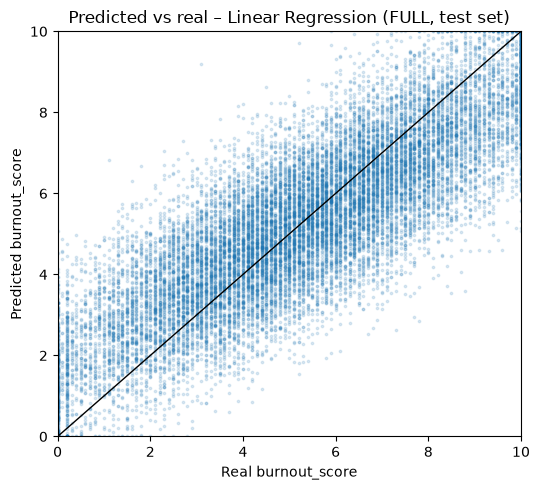

In [ ]:
pipe = best_pipes[(CHOSEN["FULL"], "FULL")]
pred = clip_score(pipe.predict(X_test))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, pred, s=3, alpha=0.15)
ax.plot([0, 10], [0, 10], color="black", linewidth=1)
ax.set_xlabel("Real burnout_score")
ax.set_ylabel("Predicted burnout_score")
ax.set_title(f"Predicted vs real – {CHOSEN['FULL']} (FULL, test set)")
ax.set_xlim(0, 10); ax.set_ylim(0, 10)
plt.tight_layout()
plt.show()

Points on the black line are perfect predictions. If the cloud is flatter than the line, the model pulls extreme employees toward the middle (it under-predicts high burnout and over-predicts low burnout), which is common in regression.

## 10. Extra: Converting the Score to Levels

This part is not needed for the regression model, but we added it because Bayyinah will display burnout as a level (Low / Moderate / High / Severe) instead of just a score.

It also helps us compare the regression model with the classification model using the same test data.

We convert the predicted scores into levels using the same ranges that were used to create `burnout_level`. Then, we compare the predicted levels with the actual ones using two measurements:

- **Far-off error rate:** Shows the percentage of employees whose predicted level is two or more levels away from their actual level. For example, predicting High when the actual level is Low.
- **QWK (Quadratic Weighted Kappa):** Measures how close the predicted levels are to the actual levels. It gives a bigger penalty when the prediction is far from the correct level than when it is only one level away.

In [ ]:
LEVEL_CODE = {lvl: i for i, lvl in enumerate(LEVELS)}

def score_to_level(score):
    return pd.cut(score, bins=[-np.inf, 3.5, 5.5, 7.0, np.inf], labels=LEVELS).astype(str)

# check: the ranges reproduce the real levels from the real scores
assert (score_to_level(y_test.values) == y_test_level.values).all(), "level ranges don't match the data"

level_rows = []
for fs in FEATURE_SETS:
    pred = clip_score(best_pipes[(CHOSEN[fs], fs)].predict(X_test))
    lv = score_to_level(pred)
    t, p = y_test_level.map(LEVEL_CODE), pd.Series(lv).map(LEVEL_CODE)
    level_rows.append({"features": fs, "model": CHOSEN[fs],
                       "accuracy": accuracy_score(y_test_level, lv),
                       "macro_F1": f1_score(y_test_level, lv, average="macro"),
                       "QWK": cohen_kappa_score(t, p, weights="quadratic"),
                       "far_off_error_%": (np.abs(t.values - p.values) >= 2).mean() * 100})
level_table = pd.DataFrame(level_rows)
display(level_table.round(4))

pred_full = clip_score(best_pipes[(CHOSEN["FULL"], "FULL")].predict(X_test))
print("\nConfusion matrix (FULL, rows = real level, columns = predicted level):")
print(pd.crosstab(y_test_level, score_to_level(pred_full), rownames=["real"], colnames=["predicted"])
        .reindex(index=LEVELS, columns=LEVELS, fill_value=0))

,features,model,accuracy,macro_F1,QWK,far_off_error_%
0,FULL,Linear Regression,0.5878,0.5857,0.7805,4.1246
1,HR,Linear Regression,0.4923,0.4940,0.6659,8.5564



Confusion matrix (FULL, rows = real level, columns = predicted level):
predicted   Low  Moderate  High  Severe
real                                   
Low        3025      1771   166       9
Moderate    719      2894  1257     181
High         76      1240  1706     677
Severe        5       355  1459    3662


**What this shows:** about 59% of employees get exactly the right level, which is way better than guessing (about 25%). Most mistakes are only one level off, like Low predicted as Moderate. Only about 4% are two or more levels away, and almost no Severe employee is predicted as Low (5 out of 5,481). High is the hardest level to get right (46%), since it sits between Moderate and Severe and gets mixed up with both. Still, 93% of Severe employees end up predicted as High or Severe, so they would still get flagged.

## 11. Explainability

Bayyinah should be able to explain *why* an employee is at risk, not just give a number. We look at this in two ways:

1. **Coefficients of the linear model:** since we scaled the numeric features, each coefficient tells us how many points the burnout score changes when that feature goes up by one standard deviation (a clear increase compared to the usual). Because all features are on the same scale, we can compare them with each other. For categorical features (like seniority level), it's better to compare the categories with each other, for example Lead vs Senior, instead of reading one number alone.
2. **Permutation importance:** we shuffle one column at a time and check how much worse the test MAE gets. If the error goes up a lot, the model really depends on that feature. This works for any model, and it treats each original column as one feature (so "country" counts as one feature, not ten one-hot columns).

Keep in mind the data is synthetic, so these results show how the data was generated, not proven causes of burnout in real life.

In [ ]:
lin = best_pipes[("Linear Regression", "FULL")]
coef = pd.Series(lin.named_steps["model"].coef_,
                 index=lin.named_steps["prep"].get_feature_names_out()).rename("coefficient")
coef.index = coef.index.str.replace(r"^(num|cat|company_size)__", "", regex=True)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
print("Top 15 linear coefficients (FULL):")
print(top.round(3).to_string())

Top 15 linear coefficients (FULL):
work_hours_per_week          1.054
meetings_per_day             0.910
sleep_hours_per_night       -0.905
vacation_days_taken         -0.744
social_support_score        -0.600
exercise_days_per_week      -0.544
manager_support_score       -0.460
deadline_pressure_score      0.383
seniority_level_Lead         0.295
autonomy_score              -0.261
seniority_level_Manager      0.225
seniority_level_Principal   -0.197
uses_therapy                -0.152
seniority_level_Senior      -0.150
gender_Female                0.147


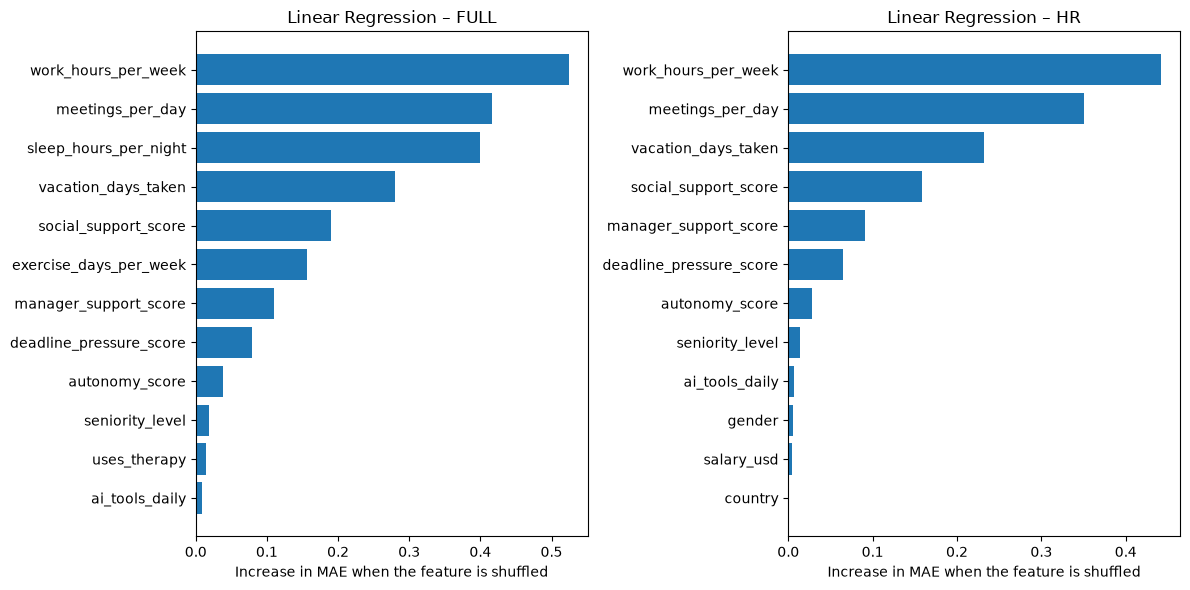

In [ ]:
imp = {}
for fs in FEATURE_SETS:
    pipe = best_pipes[(CHOSEN[fs], fs)]
    cols = FEATURE_SETS[fs]
    r = permutation_importance(pipe, X_test[cols], y_test, scoring=SCORING["MAE"],
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp[fs] = pd.Series(r.importances_mean, index=cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, fs in zip(axes, FEATURE_SETS):
    s = imp[fs].tail(12)
    ax.barh(s.index, s.values)
    ax.set_title(f"{CHOSEN[fs]} – {fs}")
    ax.set_xlabel("Increase in MAE when the feature is shuffled")
plt.tight_layout()
plt.show()

**How to read it:** the longest bars are the features the model relies on most. Features with a bar near 0 don't help the prediction (shuffling them changes nothing).

## 12. Save for the backend

We save the chosen pipeline for each feature list. Each `.pkl` contains the preprocessor **and** the model, so the backend only needs `pipeline.predict(raw_employee_data)`. Before saving, the pipeline is refitted on the full training set (already done in `record`).

We also save the test predictions, so the classification teammate can compare the two models on the same employees.

In [ ]:
os.makedirs(OUT_DIR, exist_ok=True)

for fs in FEATURE_SETS:
    joblib.dump(best_pipes[(CHOSEN[fs], fs)], f"{OUT_DIR}/burnout_regressor_{fs.lower()}.pkl")

cv_table.assign(best_params=cv_table["best_params"].astype(str)).to_csv(f"{OUT_DIR}/regression_cv_results.csv", index=False)
test_table.to_csv(f"{OUT_DIR}/regression_test_results.csv", index=False)

# test predictions in the same row order as X_test (for the classification comparison)
pd.DataFrame({"burnout_score_pred": pred_full}).to_csv(f"{PREP_DIR}/y_pred_reg_test.csv", index=False)

versions = {"pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "numpy": np.__version__, "joblib": joblib.__version__}
if HAS_XGB:
    versions["xgboost"] = xgboost.__version__

model_card = {
    "task": "regression", "target": TARGET, "prediction_range": [0, 10], "predictions_clipped": True,
    "level_ranges": {"Low": "<= 3.5", "Moderate": "<= 5.5", "High": "<= 7.0", "Severe": "> 7.0"},
    "models": {
        fs: {
            "model": CHOSEN[fs],
            "file": f"burnout_regressor_{fs.lower()}.pkl",
            "features": FEATURE_SETS[fs],
            "best_params": {k: (v.item() if hasattr(v, "item") else v)
                            for k, v in cv_table[(cv_table["model"] == CHOSEN[fs]) & (cv_table["features"] == fs)].iloc[0]["best_params"].items()},
            "cv": cv_table[(cv_table["model"] == CHOSEN[fs]) & (cv_table["features"] == fs)][["CV_MAE", "CV_RMSE", "CV_R2"]].iloc[0].round(4).to_dict(),
            "test": test_table[(test_table["model"] == CHOSEN[fs]) & (test_table["features"] == fs)][["test_MAE", "test_RMSE", "test_R2"]].iloc[0].round(4).to_dict(),
        } for fs in FEATURE_SETS
    },
    "cv": "5-fold KFold(shuffle=True, random_state=42) on the training set only",
    "random_state": RANDOM_STATE, "versions": versions, "date": str(date.today()),
}
with open(f"{OUT_DIR}/model_card.json", "w") as f:
    json.dump(model_card, f, indent=2, default=str)

for name in sorted(os.listdir(OUT_DIR)):
    print(f"{name:<34} {os.path.getsize(os.path.join(OUT_DIR, name)) / 1024:>10,.1f} KB")

burnout_regressor_full.pkl                9.2 KB
burnout_regressor_hr.pkl                  9.0 KB
model_card.json                           2.6 KB
regression_cv_results.csv                 2.8 KB
regression_test_results.csv               1.1 KB


### A prediction function for the backend

Takes one employee's raw data as a dictionary (missing values are allowed, the imputers handle them) and returns the score and the level.

In [ ]:
def predict_burnout_score(employee: dict, pipeline) -> dict:
    row = pd.DataFrame([employee]).reindex(columns=FEATURES_FULL)   # missing columns become NaN
    score = float(clip_score(pipeline.predict(row))[0])
    return {"burnout_score": round(score, 2), "burnout_level": score_to_level(np.array([score]))[0]}

model_full = joblib.load(f"{OUT_DIR}/burnout_regressor_full.pkl")
model_hr = joblib.load(f"{OUT_DIR}/burnout_regressor_hr.pkl")

example = X_test.iloc[0].to_dict()
print("Example employee      :", predict_burnout_score(example, model_full),
      "| real:", y_test.iloc[0], y_test_level.iloc[0])

messy = dict(example)
messy["salary_usd"] = None
messy["job_role"] = "Some New Role"
del messy["sleep_hours_per_night"]
print("Missing values + new role:", predict_burnout_score(messy, model_full))
print("Same employee, HR model :", predict_burnout_score(example, model_hr))

Example employee      : {'burnout_score': 4.53, 'burnout_level': 'Moderate'} | real: 4.0 Moderate
Missing values + new role: {'burnout_score': 3.53, 'burnout_level': 'Moderate'}
Same employee, HR model : {'burnout_score': 3.46, 'burnout_level': 'Low'}


## 13. Final checks

In [ ]:
for fs, model in [("FULL", model_full), ("HR", model_hr)]:
    before = best_pipes[(CHOSEN[fs], fs)].predict(X_test)
    after = model.predict(X_test)
    assert np.allclose(before, after), f"{fs}: reloaded model gives different predictions"
print("OK – the saved models give exactly the same predictions after reloading.")
print("OK – the test set was only used in sections 9–11, after the models were chosen with CV.")
print()
print("requirements.txt ->", "  ".join(f"{k}=={v}" for k, v in versions.items()))

OK – the saved models give exactly the same predictions after reloading.
OK – the test set was only used in sections 9–11, after the models were chosen with CV.

requirements.txt -> pandas==3.1.1  scikit-learn==1.9.1  numpy==2.5.4  joblib==1.6.0  xgboost==3.4.1


# Some ideas for future improvement



**1. Using the BAT questionnaire**

The model could be more accurate if we use some personal information like sleep and exercise. Since Bayyinah already plans to use a BAT questionnaire, we could add a few simple questions about these things. This might help us get better predictions for employees who answer the questions.

**2. Showing a prediction range**

Instead of showing only one predicted score, we could show a range. For example, if the model predicts 6, the actual score might be around 5 or 7. This would make the results easier to understand and avoid making the prediction look 100% accurate.
